# Kiểm thử đảo chiều

BRFSS 2017 là tập phát triển; NHANES 2015–2018 là kiểm thử ngoài riêng. Nhánh này dùng LR và XGBoost, tách khỏi kết quả NHANES → BRFSS.

## Đọc dữ liệu

BRFSS dùng chẩn đoán tự khai ngoài thai kỳ; NHANES còn dùng thuốc, HbA1c và glucose hợp lệ. Nhãn âm NHANES theo giả định quan sát ở notebook 01, nên định nghĩa nhãn giữa hai nguồn không hoàn toàn tương đương.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
import src.utils as utils

INPUT_COLS = [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
source_paths = {
    "BRFSS 2017": project_dir / "data/processed/brfss_2017.parquet",
    "NHANES 2015–2018": project_dir / "data/processed/nhanes_2015_2018.parquet",
}
for source_path in source_paths.values():
    assert source_path.is_file(), source_path
source_hashes = {name: hashlib.sha256(source_path.read_bytes()).hexdigest()
                 for name, source_path in source_paths.items()}
sources = {name: pd.read_parquet(source_path) for name, source_path in source_paths.items()}
brfss_source = sources["BRFSS 2017"]
nhanes_external = sources["NHANES 2015–2018"]
assert len(brfss_source) == 449219
assert len(nhanes_external) == 10832

## Kiểm tra đầu vào

Tuổi chặn trên ở 80, BMI dùng kg/m²; giới và chủng tộc giữ mã/nhóm đã thống nhất ở notebook 01. Bảng dưới tính mức thiếu trên toàn bộ người có nhãn, gồm cả người thiếu đầu vào.

In [2]:
expected_dtypes = {
    "age": "float64", "sex": "Int64", "race_ethnicity": "string", "bmi": "float64",
    "smoking_status": "string", "physical_activity": "Int64",
    "heart_attack": "Int64", "stroke": "Int64",
}
domains = {
    "sex": [1, 2],
    "race_ethnicity": ["White NH", "Black NH", "Hispanic", "Other"],
    "smoking_status": ["never", "former", "current"],
    "physical_activity": [0, 1], "heart_attack": [0, 1], "stroke": [0, 1],
}
sample_rows, input_rows = [], []
for name, frame in sources.items():
    assert frame.columns.is_unique and frame.columns[:8].tolist() == INPUT_COLS
    assert frame.index.is_unique and frame.index.notna().all()
    assert frame[INPUT_COLS].dtypes.astype(str).to_dict() == expected_dtypes
    labels = frame["diabetes_label"]
    assert str(labels.dtype) == "Int64" and labels.notna().all()
    assert labels.isin([0, 1]).all() and labels.nunique() == 2
    if name.startswith("BRFSS"):
        year = int(name[-4:])
        assert frame["year"].eq(year).all()
        assert {"year", "_STATE", "_PSU", "_STSTR", "_LLCPWT", "DIABETE3"}.issubset(frame.columns)
        key_name = "year × source_row_id"
    else:
        assert frame["SEQN"].notna().all() and frame["SEQN"].is_unique
        assert frame["cycle"].isin(["2015-2016", "2017-2018"]).all()
        assert {"WTINT2YR", "WTMEC2YR", "WTSAF2YR", "SDMVPSU", "SDMVSTRA"}.issubset(frame.columns)
        key_name = "SEQN"
    sample_rows.append({
        "nguồn": name, "n": len(frame), "nhãn 0": int(labels.eq(0).sum()),
        "nhãn 1": int(labels.eq(1).sum()), "nhãn 1 (%)": labels.mean() * 100,
        "khóa": key_name, "thiếu ≥1 đầu vào": int(frame[INPUT_COLS].isna().any(axis=1).sum()),
    })
    for column in INPUT_COLS:
        observed = frame[column].dropna()
        if column in ["age", "bmi"]:
            values = observed.to_numpy(dtype=float)
            assert np.isfinite(values).all()
            if column == "age":
                assert observed.between(18, 80).all() and np.equal(values, np.floor(values)).all()
            else:
                assert observed.gt(0).all()
                if name.startswith("BRFSS"):
                    assert observed.le(99.99).all()
            observed_domain = f"{observed.min():g}–{observed.max():g}"
        else:
            assert observed.isin(domains[column]).all(), (name, column)
            observed_domain = ", ".join(map(str, sorted(observed.unique())))
        input_rows.append({
            "nguồn": name, "biến": column, "dtype": str(frame[column].dtype),
            "miền quan sát": observed_domain, "số thiếu": int(frame[column].isna().sum()),
            "thiếu (%)": frame[column].isna().mean() * 100,
        })
sample_audit = pd.DataFrame(sample_rows)
input_audit = pd.DataFrame(input_rows)
display(sample_audit.round({"nhãn 1 (%)": 2}))
display(input_audit.round({"thiếu (%)": 2}))

,nguồn,n,nhãn 0,nhãn 1,nhãn 1 (%),khóa,thiếu ≥1 đầu vào
0,BRFSS 2017,449219,388779,60440,13.45,year × source_row_id,82115
1,NHANES 2015–2018,10832,8558,2274,20.99,SEQN,754


,nguồn,biến,dtype,miền quan sát,số thiếu,thiếu (%)
0,BRFSS 2017,age,float64,18–80,0,0.00
1,BRFSS 2017,sex,Int64,"1, 2",276,0.06
2,BRFSS 2017,race_ethnicity,string,"Black NH, Hispanic, Other, White NH",8662,1.93
3,BRFSS 2017,bmi,float64,12.01–99.31,36212,8.06
4,BRFSS 2017,smoking_status,string,"current, former, never",18625,4.15
5,BRFSS 2017,physical_activity,Int64,"0, 1",49932,11.12
6,BRFSS 2017,heart_attack,Int64,"0, 1",2218,0.49
7,BRFSS 2017,stroke,Int64,"0, 1",1212,0.27
8,NHANES 2015–2018,age,float64,18–80,0,0.00
9,NHANES 2015–2018,sex,Int64,"1, 2",0,0.00


## Tập phát triển

Lấy source_row_id từ index nguồn BRFSS 2017. Năm và các biến khảo sát nằm ở bảng hỗ trợ, ngoài 8 đầu vào.

In [3]:
brfss_development = brfss_source.assign(source_row_id=brfss_source.index.to_numpy(copy=True))
assert len(brfss_development) == 449219 and brfss_development["year"].eq(2017).all()
assert brfss_development["source_row_id"].notna().all() and brfss_development["source_row_id"].is_unique
np.testing.assert_array_equal(brfss_development["source_row_id"], brfss_source.index)
pd.testing.assert_frame_equal(brfss_development[brfss_source.columns], brfss_source)

X_development = brfss_development[INPUT_COLS].copy()
y_development = brfss_development["diabetes_label"].copy()
development_support = brfss_development.drop(columns=INPUT_COLS + ["diabetes_label"]).copy()
X_external = nhanes_external[INPUT_COLS].copy()
y_external = nhanes_external["diabetes_label"].copy()
external_support = nhanes_external.drop(columns=INPUT_COLS + ["diabetes_label"]).copy()

assert X_development.shape == (449219, 8) and X_external.shape == (10832, 8)
assert X_development.columns.tolist() == X_external.columns.tolist() == INPUT_COLS
assert X_development.dtypes.equals(X_external.dtypes)
assert X_development.index.equals(y_development.index) and X_development.index.equals(development_support.index)
assert X_external.index.equals(y_external.index) and X_external.index.equals(external_support.index)
pd.testing.assert_series_equal(y_development, brfss_source["diabetes_label"])
pd.testing.assert_series_equal(y_external, nhanes_external["diabetes_label"])
pd.testing.assert_frame_equal(X_external, nhanes_external[INPUT_COLS])
pd.crosstab(development_support["year"], y_development).reindex(columns=[0, 1])

diabetes_label,0,1
year,,
2017,388779,60440


## Pipeline

LR dùng median/mode, one-hot và scaling; XGBoost không scaling. Tiền xử lý và trọng số lớp học từ train của từng fold.

In [4]:
reusable_functions = [
    (utils.build_preprocessor, "Tiền xử lý mới cho mỗi train fold"),
    (utils.build_tuning_pipeline, "LR balanced; XGBoost tính scale_pos_weight từ y mỗi lần fit"),
    (utils.get_tuning_space, "Miền tìm kiếm hiện có, nếu chốt tối ưu"),
    (utils.get_model_metrics, "Bảy metric đối chiếu baseline; precision/F1 dùng zero_division=0"),
    (utils.get_binary_group_metrics, "Metric theo ngưỡng và xác suất; tỷ số không xác định là NA"),
    (utils.get_youden_threshold, "Có thể dùng cho ngưỡng phát triển từ OOF BRFSS"),
]
assert all(callable(function) for function, _ in reusable_functions)
display(pd.DataFrame([{"hàm": function.__name__, "công dụng": purpose}
                      for function, purpose in reusable_functions]))

reverse_dirs = {
    "models": project_dir / "models/reverse_validation",
    "results": project_dir / "results/brfss_to_nhanes",
}
for directory in reverse_dirs.values():
    directory.mkdir(parents=True, exist_ok=True)
assert reverse_dirs["models"] != project_dir / "models/final"
assert reverse_dirs["results"] != project_dir / "results/nhanes_to_brfss/external_validation"


,hàm,công dụng
0,build_preprocessor,Tiền xử lý mới cho mỗi train fold
1,build_tuning_pipeline,LR balanced; XGBoost tính scale_pos_weight từ ...
2,get_tuning_space,"Miền tìm kiếm hiện có, nếu chốt tối ưu"
3,get_model_metrics,Bảy metric đối chiếu baseline; precision/F1 dù...
4,get_binary_group_metrics,Metric theo ngưỡng và xác suất; tỷ số không xá...
5,get_youden_threshold,Có thể dùng cho ngưỡng phát triển từ OOF BRFSS


## Bảng kiểm tra

In [5]:
for name, source_path in source_paths.items():
    assert hashlib.sha256(source_path.read_bytes()).hexdigest() == source_hashes[name]
display(sample_audit.round({"nhãn 1 (%)": 2}))

,nguồn,n,nhãn 0,nhãn 1,nhãn 1 (%),khóa,thiếu ≥1 đầu vào
0,BRFSS 2017,449219,388779,60440,13.45,year × source_row_id,82115
1,NHANES 2015–2018,10832,8558,2274,20.99,SEQN,754


## Chia CV

Phân tầng theo nhãn bệnh, dùng chung 5 fold cho LR và XGBoost. Chỉ số fold là vị trí dòng, còn source_row_id dùng đối chiếu người.

In [6]:
from sklearn.model_selection import StratifiedKFold

SEED = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = [(train.copy(), valid.copy()) for train, valid in cv.split(X_development, y_development)]
coverage = np.zeros(len(X_development), dtype=int)
fold_rows = []
for fold, (train, valid) in enumerate(cv_splits, 1):
    train_ids = development_support.iloc[train]["source_row_id"]
    valid_ids = development_support.iloc[valid]["source_row_id"]
    assert not np.intersect1d(train_ids, valid_ids).size
    assert np.array_equal(np.sort(np.r_[train, valid]), np.arange(len(X_development)))
    assert X_development.iloc[train].index.equals(y_development.iloc[train].index)
    assert X_development.iloc[valid].index.equals(y_development.iloc[valid].index)
    coverage[valid] += 1
    for partition, indices in [("train", train), ("validation", valid)]:
        labels = y_development.iloc[indices]
        fold_rows.append({"fold": fold, "phần": partition, "n": len(labels),
                          "nhãn 0": int(labels.eq(0).sum()), "nhãn 1": int(labels.eq(1).sum())})
assert np.all(coverage == 1) and len(cv_splits) == 5
display(pd.DataFrame(fold_rows))

,fold,phần,n,nhãn 0,nhãn 1
0,1,train,359375,311023,48352
1,1,validation,89844,77756,12088
2,2,train,359375,311023,48352
3,2,validation,89844,77756,12088
4,3,train,359375,311023,48352
5,3,validation,89844,77756,12088
6,4,train,359375,311023,48352
7,4,validation,89844,77756,12088
8,5,train,359376,311024,48352
9,5,validation,89843,77755,12088


## Pilot

Mỗi mô hình dùng một cấu hình pilot từ notebook 03 qua đủ 5 fold, mỗi fold tạo pipeline mới. AUC tính từ xác suất, chưa áp trọng số khảo sát.

In [7]:
import ast
import json

modeling_path = project_dir / "notebooks/03_modeling.ipynb"
modeling_cells = json.loads(modeling_path.read_text(encoding="utf-8"))["cells"]
config_cell = next(cell for cell in modeling_cells
                   if cell["cell_type"] == "code" and "pilot_params = " in "".join(cell["source"]))
assignment = next(node for node in ast.parse("".join(config_cell["source"])).body
                  if isinstance(node, ast.Assign) and any(
                      isinstance(target, ast.Name) and target.id == "pilot_params" for target in node.targets))
existing_pilot_params = ast.literal_eval(assignment.value)
pilot_params = {model: existing_pilot_params[model] for model in ["LR", "XGBoost"]}
assert pilot_params == {
    "LR": {"C": 1.0},
    "XGBoost": {"learning_rate": 0.05, "max_depth": 3, "n_estimators": 200,
                "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 1},
}
pilot_result = utils.run_reverse_pilot(
    X_development, y_development, development_support, cv_splits,
    pilot_params, reverse_dirs["results"], seed=SEED,
)

## AUC và thời gian

Ước tính 30 trial bằng 30 × tổng thời gian fit/predict của 5 fold pilot, không gồm fit cuối. Chi phí thực tế có thể thay đổi theo cấu hình và tải máy.

In [8]:
pilot_folds = pilot_result["folds"]
pilot_summary = pilot_result["summary"]
assert len(pilot_folds) == 10 and pilot_folds.groupby("model")["fold"].nunique().eq(5).all()
assert pilot_folds["auc"].between(0, 1).all()
for name, source_path in source_paths.items():
    assert hashlib.sha256(source_path.read_bytes()).hexdigest() == source_hashes[name]
assert not hasattr(X_external, "probability")
warning_counts = pilot_result["warnings"].groupby("model").size()
summary_display = pilot_summary.assign(
    warning_count=warning_counts.reindex(pilot_summary.index, fill_value=0)
)
display(pilot_folds[["model", "fold", "train_n", "valid_n", "auc",
                     "fit_seconds", "predict_seconds"]].round(4))
display(summary_display.round(4))
display(pd.DataFrame([{"pilot_run_id": pilot_result["id"],
                       "kết quả": str(pilot_result["directory"])}]))

,model,fold,train_n,valid_n,auc,fit_seconds,predict_seconds
0,LR,1,359375,89844,0.7768,2.5217,0.2780
1,LR,2,359375,89844,0.7820,2.5746,0.2818
2,LR,3,359375,89844,0.7794,2.4459,0.2920
3,LR,4,359375,89844,0.7748,2.4034,0.2992
4,LR,5,359376,89843,0.7810,2.4361,0.2927
5,XGBoost,1,359375,89844,0.7843,5.8913,0.3371
6,XGBoost,2,359375,89844,0.7895,5.4101,0.3424
7,XGBoost,3,359375,89844,0.7871,5.3711,0.3657
8,XGBoost,4,359375,89844,0.7827,5.4815,0.3892
9,XGBoost,5,359376,89843,0.7893,5.4582,0.3266


,folds,auc_mean,auc_sd,fit_seconds,predict_seconds,pilot_seconds,estimated_30_trials_minutes,warning_count
model,,,,,,,,
LR,5,0.7788,0.003,12.3816,1.4438,13.8254,6.9127,0
XGBoost,5,0.7866,0.003,27.6122,1.7610,29.3732,14.6866,0


,pilot_run_id,kết quả
0,37d7ba48f973e904,D:\NCKH Mini\diabetes-project\results\reverse_...


## Tối ưu chính thức

LR và XGBoost dùng chung 5 fold BRFSS 2017 đã lưu, tối đa hóa ROC-AUC trung bình bằng Optuna TPE, 30 trial COMPLETE mỗi mô hình. Miền tìm kiếm giữ như nhánh trước; tiền xử lý và trọng số lớp học từ train của từng lần fit, không áp trọng số khảo sát hay calibration bổ sung.

Điểm CV chọn tham số và OOF phát triển ngưỡng dùng cùng mẫu, không phải đánh giá nội bộ độc lập như outer OOF của nested CV.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
import src.utils as utils

source_path = project_dir / "data/processed/brfss_2017.parquet"
source_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
brfss_official = pd.read_parquet(source_path)
INPUT_COLS = [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
assert brfss_official.columns[:8].tolist() == INPUT_COLS
assert brfss_official.index.is_unique and brfss_official.index.notna().all()
X_official = brfss_official[INPUT_COLS].copy()
y_official = brfss_official["diabetes_label"].copy()
support_official = brfss_official.drop(columns=INPUT_COLS + ["diabetes_label"]).copy()
support_official["source_row_id"] = brfss_official.index.to_numpy(copy=True)
assert X_official.shape == (449219, 8)
assert y_official.value_counts().to_dict() == {0: 388779, 1: 60440}
pilot_dir = project_dir / "results/brfss_to_nhanes/pilot/37d7ba48f973e904"
official_run = utils.prepare_reverse_run(
    X_official, y_official, support_official, pilot_dir,
    project_dir / "results/brfss_to_nhanes", project_dir / "models/reverse_validation",
    seed=42, budget=30,
)
assert official_run["config"]["space"] == {
    model: utils.get_tuning_space()[model] for model in ["LR", "XGBoost"]
}
official_results = {}
display(pd.DataFrame([{
    "run_id": official_run["id"], "n": len(X_official),
    "fold": len(official_run["splits"]), "trial COMPLETE/mô hình": 30,
}]))

,run_id,n,fold,trial COMPLETE/mô hình
0,58ba2320a9141ff0,449219,5,30


## LR

In [2]:
official_results["LR"] = utils.fit_reverse_development(
    "LR", X_official, y_official, support_official, official_run,
)
display(pd.DataFrame([{
    "model": "LR", "best_params": official_results["LR"]["best_params"],
    "best_mean_cv_auc": official_results["LR"]["best_mean_cv_auc"],
    "youden": official_results["LR"]["thresholds"]["youden"],
    "complete": official_results["LR"]["complete_trials"],
    "failed": official_results["LR"]["failed_trials"],
    "seconds": official_results["LR"]["wall_seconds"],
}]))

D:\NCKH Mini\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,model,best_params,best_mean_cv_auc,youden,complete,failed,seconds
0,LR,{'C': 29.13831224000588},0.778794,0.471203,30,0,250.807817


## XGBoost

In [3]:
official_results["XGBoost"] = utils.fit_reverse_development(
    "XGBoost", X_official, y_official, support_official, official_run,
)
display(pd.DataFrame([{
    "model": "XGBoost", "best_params": official_results["XGBoost"]["best_params"],
    "best_mean_cv_auc": official_results["XGBoost"]["best_mean_cv_auc"],
    "youden": official_results["XGBoost"]["thresholds"]["youden"],
    "complete": official_results["XGBoost"]["complete_trials"],
    "failed": official_results["XGBoost"]["failed_trials"],
    "seconds": official_results["XGBoost"]["wall_seconds"],
}]))

,model,best_params,best_mean_cv_auc,youden,complete,failed,seconds
0,XGBoost,"{'learning_rate': 0.07874356006336057, 'max_de...",0.78735,0.500733,30,0,746.135727


## Tham số và ngưỡng

Youden lấy từ OOF BRFSS bằng ngưỡng hữu hạn có J cao nhất, hòa thì lấy ngưỡng cao hơn. Giữ cả ngưỡng 0,5 và Youden để dùng cố định cho kiểm thử ngoài.

In [4]:
summary_rows = []
for model, result in official_results.items():
    oof = pd.read_parquet(utils.resolve_project_path(result["oof_path"]))
    assert len(oof) == 449219 and oof.index.equals(X_official.index)
    assert oof["source_row_id"].is_unique and oof["year"].eq(2017).all()
    pd.testing.assert_frame_equal(oof[["year", "source_row_id"]], support_official[["year", "source_row_id"]])
    pd.testing.assert_series_equal(oof["diabetes_label"], y_official)
    assert oof["probability"].notna().all() and oof["probability"].between(0, 1).all()
    for fold, (_, valid) in enumerate(official_run["splits"], 1):
        assert oof.iloc[valid]["fold"].eq(fold).all()
    assert result["complete_trials"] == 30
    summary_rows.append({
        "model": model, "best_params": result["best_params"],
        "best_mean_cv_auc": result["best_mean_cv_auc"],
        "default_threshold": result["thresholds"]["default"],
        "youden_threshold": result["thresholds"]["youden"],
        "complete_trials": result["complete_trials"], "failed_trials": result["failed_trials"],
        "warning_count": result["warning_count"],
        "trial_seconds": result["trial_seconds"], "oof_seconds": result["oof_seconds"],
        "final_fit_seconds": result["final_fit_seconds"], "wall_seconds": result["wall_seconds"],
        "serialization_max_abs_error": result["serialization_max_abs_error"],
    })
assert hashlib.sha256(source_path.read_bytes()).hexdigest() == source_hash
official_summary = pd.DataFrame(summary_rows)
official_summary.to_csv(official_run["directory"] / "summary.csv", index=False)
display(official_summary)
display(pd.DataFrame([{"kết quả": str(official_run["directory"]),
                       "pipeline": str(official_run["model_directory"])}]))

,model,best_params,best_mean_cv_auc,default_threshold,youden_threshold,complete_trials,failed_trials,warning_count,trial_seconds,oof_seconds,final_fit_seconds,wall_seconds,serialization_max_abs_error
0,LR,{'C': 29.13831224000588},0.778794,0.5,0.471203,30,0,0,229.932045,12.419143,1.033316,250.807817,0.0
1,XGBoost,"{'learning_rate': 0.07874356006336057, 'max_de...",0.787350,0.5,0.500733,30,0,0,715.788857,20.614082,3.422405,746.135727,0.0


,kết quả,pipeline
0,D:\NCKH Mini\diabetes-project\results\reverse_...,D:\NCKH Mini\diabetes-project\models\reverse_v...


## Kiểm thử ngoài NHANES

Dùng pipeline BRFSS 2017 và hai ngưỡng đã lưu của reverse run. Metric chưa áp trọng số khảo sát; định nghĩa nhãn hai nguồn giữ như phần đầu notebook.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_curve, precision_recall_curve

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
import src.utils as utils

REVERSE_RUN_ID = "58ba2320a9141ff0"
development_dir = project_dir / "results/brfss_to_nhanes/final_development" / REVERSE_RUN_ID
models_dir = project_dir / "models/reverse_validation" / REVERSE_RUN_ID
external_dir = project_dir / "results/brfss_to_nhanes/external_validation" / REVERSE_RUN_ID
figures_dir = project_dir / "results/brfss_to_nhanes/figures/external_validation" / REVERSE_RUN_ID
external_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
config_path = development_dir / "config.json"
reverse_config = json.loads(config_path.read_text(encoding="utf-8"))
INPUT_COLS = [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
assert reverse_config["stage"] == "reverse_official"
assert reverse_config["development"] == "BRFSS 2017" and reverse_config["rows"] == 449219
assert reverse_config["columns"] == INPUT_COLS
assert reverse_config["models"] == ["LR", "XGBoost"]
frozen_hashes = {config_path: hashlib.sha256(config_path.read_bytes()).hexdigest()}
pipelines, reverse_metadata, reverse_thresholds, memory_hashes = {}, {}, {}, {}
for model in ["LR", "XGBoost"]:
    artifact_path = development_dir / model / "artifacts.json"
    artifact = json.loads(artifact_path.read_text(encoding="utf-8"))
    assert artifact["run_id"] == REVERSE_RUN_ID
    paths = {
        "pipeline": models_dir / f"{model}.joblib",
        "metadata": development_dir / model / "metadata.json",
        "thresholds": development_dir / model / "thresholds.json",
        "model_metadata": models_dir / f"{model}.metadata.json",
        "run_metadata": models_dir / f"{model}.run.json",
    }
    for item in paths.values():
        digest = hashlib.sha256(item.read_bytes()).hexdigest()
        assert digest == utils.get_manifest_artifact_hash(artifact["sha256"], item, project_dir)
        frozen_hashes[item] = digest
    frozen_hashes[artifact_path] = hashlib.sha256(artifact_path.read_bytes()).hexdigest()
    metadata = json.loads(paths["metadata"].read_text(encoding="utf-8"))
    assert metadata["run_id"] == REVERSE_RUN_ID and metadata["model"] == model
    assert metadata["stage"] == "reverse_official" and metadata["config"] == reverse_config
    assert json.loads(paths["run_metadata"].read_text(encoding="utf-8")) == metadata
    thresholds = json.loads(paths["thresholds"].read_text(encoding="utf-8"))
    assert thresholds == metadata["thresholds"] and thresholds["default"] == 0.5
    assert np.isfinite(thresholds["youden"])
    model_metadata = json.loads(paths["model_metadata"].read_text(encoding="utf-8"))
    assert model_metadata["identity"]["run_id"] == REVERSE_RUN_ID
    assert model_metadata["identity"]["model"] == model
    assert model_metadata["model_sha256"] == frozen_hashes[paths["pipeline"]]
    pipeline = joblib.load(paths["pipeline"])
    assert pipeline.feature_names_in_.tolist() == INPUT_COLS
    assert pipeline.named_steps["preprocessor"].feature_names_in_.tolist() == INPUT_COLS
    np.testing.assert_array_equal(pipeline.classes_, [0, 1])
    for parameter, value in metadata["best_params"].items():
        assert pipeline.named_steps["classifier"].get_params()[parameter] == value
    pipelines[model], reverse_metadata[model], reverse_thresholds[model] = pipeline, metadata, thresholds
    memory_hashes[model] = joblib.hash(pipeline)

nhanes_path = project_dir / "data/processed/nhanes_2015_2018.parquet"
frozen_hashes[nhanes_path] = hashlib.sha256(nhanes_path.read_bytes()).hexdigest()
nhanes_test = pd.read_parquet(nhanes_path)
nhanes_before = nhanes_test.copy(deep=True)
X_nhanes = nhanes_test[INPUT_COLS].copy()
y_nhanes = nhanes_test["diabetes_label"].copy()
assert X_nhanes.shape == (10832, 8) and X_nhanes.columns.tolist() == INPUT_COLS
assert X_nhanes.dtypes.astype(str).to_dict() == reverse_config["dtypes"]
assert nhanes_test.index.is_unique and X_nhanes.index.equals(y_nhanes.index)
assert X_nhanes.index.equals(nhanes_test[["SEQN", "cycle"]].index)
assert nhanes_test["SEQN"].notna().all() and nhanes_test["SEQN"].is_unique
assert not nhanes_test[["SEQN", "cycle"]].duplicated().any()
assert nhanes_test["cycle"].notna().all()
assert set(nhanes_test["cycle"]) == {"2015-2016", "2017-2018"}
assert y_nhanes.notna().all() and y_nhanes.value_counts().to_dict() == {0: 8558, 1: 2274}
assert X_nhanes["age"].dropna().between(18, 80).all()
assert np.isfinite(X_nhanes[["age", "bmi"]].to_numpy(dtype=float)[
    ~np.isnan(X_nhanes[["age", "bmi"]].to_numpy(dtype=float))]).all()
assert X_nhanes["bmi"].dropna().gt(0).all()
domains = {
    "sex": [1, 2], "race_ethnicity": ["White NH", "Black NH", "Hispanic", "Other"],
    "smoking_status": ["never", "former", "current"],
    "physical_activity": [0, 1], "heart_attack": [0, 1], "stroke": [0, 1],
}
for column, values in domains.items():
    assert X_nhanes[column].dropna().isin(values).all()
input_check = pd.DataFrame({
    "feature": INPUT_COLS, "dtype": X_nhanes.dtypes.astype(str).to_numpy(),
    "missing": X_nhanes.isna().sum().to_numpy(),
    "missing_percent": X_nhanes.isna().mean().to_numpy() * 100,
})
input_check.to_csv(external_dir / "input_check.csv", index=False)
display(input_check.round({"missing_percent": 2}))
display(pd.DataFrame([{"model": model, "development": reverse_metadata[model]["config"]["development"],
                       "default_threshold": item["default"], "youden_brfss": item["youden"]}
                      for model, item in reverse_thresholds.items()]))

,feature,dtype,missing,missing_percent
0,age,float64,0,0.00
1,sex,Int64,0,0.00
2,race_ethnicity,string,0,0.00
3,bmi,float64,228,2.10
4,smoking_status,string,9,0.08
5,physical_activity,Int64,25,0.23
6,heart_attack,Int64,499,4.61
7,stroke,Int64,495,4.57


,model,development,default_threshold,youden_brfss
0,LR,BRFSS 2017,0.5,0.471203
1,XGBoost,BRFSS 2017,0.5,0.500733


## Metric ngoài mẫu

Bảng chính dùng toàn NHANES, bảng phụ tách chu kỳ. Người thiếu đầu vào vẫn được dự đoán bằng tiền xử lý đã học từ BRFSS.

In [2]:
nhanes_predictions, metric_rows, calibration_rows = {}, [], []
for model, pipeline in pipelines.items():
    probability = pipeline.predict_proba(X_nhanes)[:, 1]
    assert probability.shape == (len(y_nhanes),) and np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    prediction = nhanes_test[["SEQN", "cycle", "diabetes_label"]].copy()
    prediction["probability"] = probability
    prediction["prediction_0_5"] = prediction["probability"].ge(reverse_thresholds[model]["default"]).astype("Int64")
    prediction["prediction_youden"] = prediction["probability"].ge(reverse_thresholds[model]["youden"]).astype("Int64")
    for column in INPUT_COLS:
        prediction[column] = nhanes_test[column]
    original_columns = ["SEQN", "cycle", "diabetes_label"] + INPUT_COLS
    pd.testing.assert_frame_equal(prediction[original_columns], nhanes_test[original_columns])
    assert len(prediction) == 10832 and prediction["SEQN"].is_unique
    prediction_path = external_dir / f"nhanes_{model}_predictions.parquet"
    prediction.to_parquet(prediction_path, index=True)
    pd.testing.assert_frame_equal(pd.read_parquet(prediction_path), prediction, check_exact=True)
    nhanes_predictions[model] = prediction

    scopes = [("all", prediction)] + list(prediction.groupby("cycle", sort=True))
    for scope, subset in scopes:
        for name, column in [("default", "prediction_0_5"), ("youden", "prediction_youden")]:
            metrics = utils.get_binary_group_metrics(
                subset["diabetes_label"], subset["probability"], subset[column]
            )
            metric_rows.append({
                "model": model, "scope": scope, "threshold_name": name,
                "threshold": reverse_thresholds[model][name], **metrics,
            })
    groups = utils.get_calibration_bins(y_nhanes, probability).assign(model=model)
    calibration_rows.append(groups)
    assert joblib.hash(pipeline) == memory_hashes[model]

metrics = pd.DataFrame(metric_rows).rename(columns={"tpr": "sensitivity"})
overall_metrics = metrics.loc[metrics["scope"].eq("all")].drop(columns="scope").reset_index(drop=True)
cycle_metrics = metrics.loc[~metrics["scope"].eq("all")].rename(columns={"scope": "cycle"}).reset_index(drop=True)
probability_columns = ["model", "n", "n_positive", "n_negative", "positive_rate",
                       "roc_auc", "average_precision", "brier"]
probability_metrics = overall_metrics.loc[overall_metrics["threshold_name"].eq("default"), probability_columns]
threshold_columns = ["model", "threshold_name", "threshold", "sensitivity", "specificity",
                     "ppv", "npv", "f1", "tn", "fp", "fn", "tp", "predicted_positive_rate"]
threshold_metrics = overall_metrics[threshold_columns]
for model in pipelines:
    for name in ["default", "youden"]:
        total = overall_metrics.query("model == @model and threshold_name == @name").iloc[0]
        parts = cycle_metrics.query("model == @model and threshold_name == @name")
        assert len(parts) == 2
        for column in ["n", "n_positive", "n_negative", "tn", "fp", "fn", "tp"]:
            assert parts[column].sum() == total[column]
overall_metrics.to_csv(external_dir / "overall_metrics.csv", index=False, na_rep="NA")
cycle_metrics.to_csv(external_dir / "cycle_metrics.csv", index=False, na_rep="NA")
probability_metrics.to_csv(external_dir / "probability_metrics.csv", index=False, na_rep="NA")
threshold_metrics.to_csv(external_dir / "threshold_metrics.csv", index=False, na_rep="NA")
calibration_table = pd.concat(calibration_rows, ignore_index=True)[[
    "model", "quantile_group", "lower_bound", "upper_bound", "n", "mean_probability", "positive_rate",
]]
calibration_table.to_csv(external_dir / "calibration_quantile_bins.csv", index=False)
display(probability_metrics.round(6))
display(threshold_metrics.round(6))
display(cycle_metrics[["model", "cycle", "threshold_name", "n", "n_positive", "positive_rate",
                       "roc_auc", "average_precision", "brier", "sensitivity", "specificity",
                       "ppv", "npv", "f1", "tn", "fp", "fn", "tp"]].round(6))

,model,n,n_positive,n_negative,positive_rate,roc_auc,average_precision,brier
0,LR,10832,2274,8558,0.209934,0.789867,0.453029,0.209143
2,XGBoost,10832,2274,8558,0.209934,0.797822,0.472544,0.201333


,model,threshold_name,threshold,sensitivity,specificity,ppv,npv,f1,tn,fp,fn,tp,predicted_positive_rate
0,LR,default,0.500000,0.813105,0.636364,0.372707,0.927610,0.511126,5446,3112,425,1849,0.457995
1,LR,youden,0.471203,0.835972,0.603879,0.359289,0.932684,0.502578,5168,3390,373,1901,0.488460
2,XGBoost,default,0.500000,0.827617,0.629586,0.372526,0.932180,0.513787,5388,3170,392,1882,0.466396
3,XGBoost,youden,0.500733,0.826297,0.630404,0.372670,0.931779,0.513669,5395,3163,395,1879,0.465473


,model,cycle,threshold_name,n,n_positive,positive_rate,roc_auc,average_precision,brier,sensitivity,specificity,ppv,npv,f1,tn,fp,fn,tp
0,LR,2015-2016,default,5502,1105,0.200836,0.789852,0.446052,0.204909,0.793665,0.653855,0.365569,0.926523,0.500571,2875,1522,228,877
1,LR,2015-2016,youden,5502,1105,0.200836,0.789852,0.446052,0.204909,0.820814,0.625881,0.355408,0.932881,0.496035,2752,1645,198,907
2,LR,2017-2018,default,5330,1169,0.219325,0.789604,0.462181,0.213514,0.831480,0.617880,0.379391,0.928829,0.521040,2571,1590,197,972
3,LR,2017-2018,youden,5330,1169,0.219325,0.789604,0.462181,0.213514,0.850299,0.580630,0.362906,0.932459,0.508700,2416,1745,175,994
4,XGBoost,2015-2016,default,5502,1105,0.200836,0.797726,0.463984,0.196440,0.810860,0.649989,0.367967,0.931855,0.506215,2858,1539,209,896
5,XGBoost,2015-2016,youden,5502,1105,0.200836,0.797726,0.463984,0.196440,0.809955,0.650898,0.368313,0.931641,0.506365,2862,1535,210,895
6,XGBoost,2017-2018,default,5330,1169,0.219325,0.797487,0.482289,0.206383,0.843456,0.608027,0.376767,0.932547,0.520866,2530,1631,183,986
7,XGBoost,2017-2018,youden,5330,1169,0.219325,0.797487,0.482289,0.206383,0.841745,0.608748,0.376723,0.931935,0.520497,2533,1628,185,984


## ROC và precision–recall

Đường tham chiếu PR là tỷ lệ nhãn 1 trong mẫu NHANES.

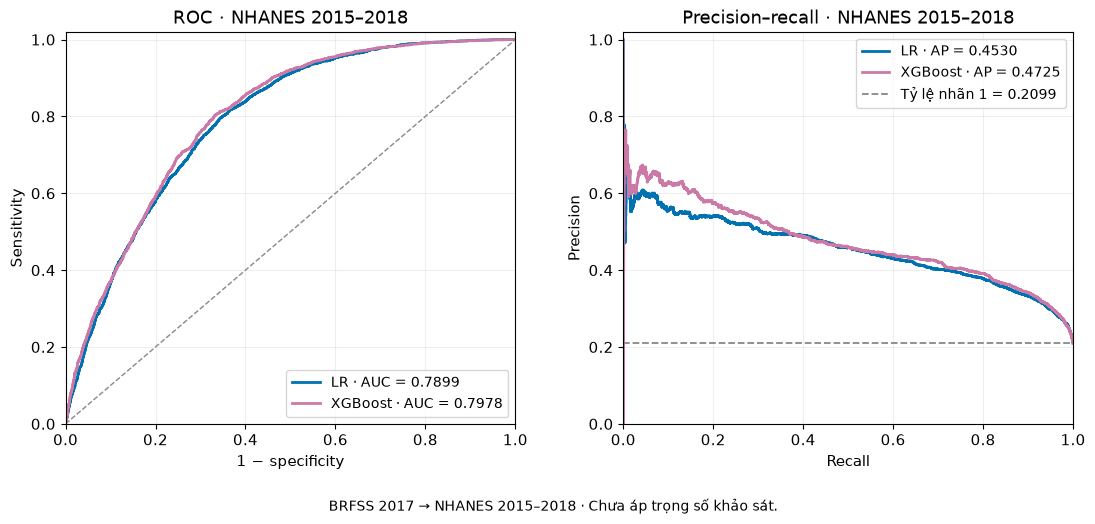

In [3]:
model_colors = {"LR": "#0072B2", "XGBoost": "#CC79A7"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 13, "axes.labelsize": 11, "legend.fontsize": 10})
figure_paths = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for model, prediction in nhanes_predictions.items():
    row = probability_metrics.loc[probability_metrics["model"].eq(model)].iloc[0]
    fpr, tpr, _ = roc_curve(prediction["diabetes_label"], prediction["probability"])
    precision, recall, _ = precision_recall_curve(
        prediction["diabetes_label"], prediction["probability"], drop_intermediate=True
    )
    axes[0].plot(fpr, tpr, color=model_colors[model], linewidth=2,
                 label=f"{model} · AUC = {row['roc_auc']:.4f}")
    axes[1].step(recall, precision, where="post", color=model_colors[model], linewidth=2,
                 label=f"{model} · AP = {row['average_precision']:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="#888888", linewidth=1)
axes[1].axhline(y_nhanes.mean(), linestyle="--", color="#888888", linewidth=1.3,
                label=f"Tỷ lệ nhãn 1 = {y_nhanes.mean():.4f}")
axes[0].set(title="ROC · NHANES 2015–2018", xlabel="1 − specificity", ylabel="Sensitivity")
axes[1].set(title="Precision–recall · NHANES 2015–2018", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.grid(alpha=0.2)
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper right")
fig.subplots_adjust(bottom=0.20, top=0.90, wspace=0.24)
fig.text(0.5, 0.045, "BRFSS 2017 → NHANES 2015–2018 · Chưa áp trọng số khảo sát.", ha="center", fontsize=10)
figure_paths.append(utils.save_png(fig, figures_dir / "nhanes_roc_pr.png"))
plt.show()
plt.close(fig)

## Calibration

Dùng xác suất gốc, chia 10 nhóm quantile cho từng mô hình. Xác suất bằng nhau nằm cùng nhóm nên số người có thể lệch nhau.

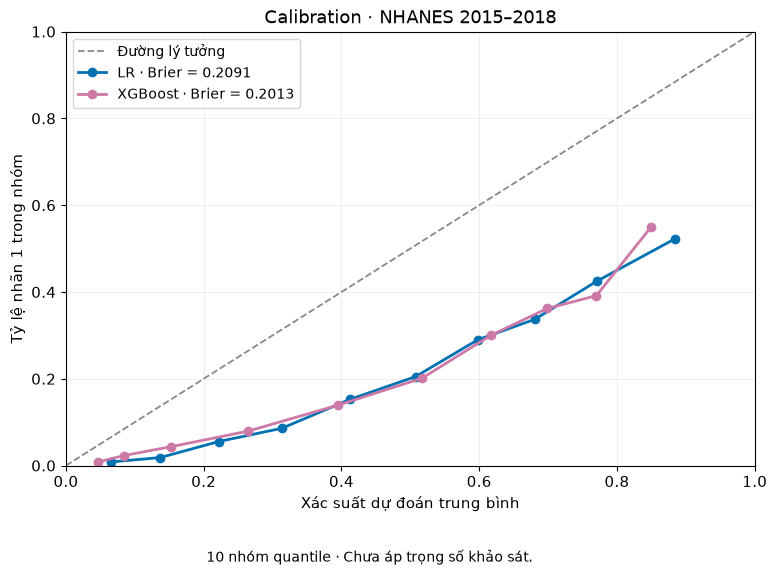

,model,quantile_group,n,mean_probability,positive_rate
0,LR,1,1084,0.065682,0.008303
1,LR,2,1083,0.136999,0.018467
2,LR,3,1083,0.221896,0.055402
3,LR,4,1083,0.313413,0.085873
4,LR,5,1083,0.412143,0.152355
5,LR,6,1083,0.507542,0.204986
6,LR,7,1083,0.598000,0.289935
7,LR,8,1083,0.680790,0.337027
8,LR,9,1083,0.770632,0.424746
9,LR,10,1084,0.883838,0.522140


In [4]:
fig, ax = plt.subplots(figsize=(8.2, 6.2))
ax.plot([0, 1], [0, 1], "--", color="#888888", linewidth=1.3, label="Đường lý tưởng")
for model in pipelines:
    groups = calibration_table.loc[calibration_table["model"].eq(model) & calibration_table["n"].gt(0)]
    row = probability_metrics.loc[probability_metrics["model"].eq(model)].iloc[0]
    ax.plot(groups["mean_probability"], groups["positive_rate"], marker="o",
            color=model_colors[model], linewidth=2, label=f"{model} · Brier = {row['brier']:.4f}")
    assert groups["n"].sum() == len(nhanes_test)
ax.set(title="Calibration · NHANES 2015–2018", xlabel="Xác suất dự đoán trung bình",
       ylabel="Tỷ lệ nhãn 1 trong nhóm", xlim=(0, 1), ylim=(0, 1))
ax.grid(alpha=0.2)
ax.legend(loc="upper left")
fig.subplots_adjust(bottom=0.20, top=0.90, left=0.13, right=0.97)
fig.text(0.5, 0.045, "10 nhóm quantile · Chưa áp trọng số khảo sát.", ha="center", fontsize=10)
figure_paths.append(utils.save_png(fig, figures_dir / "nhanes_calibration.png"))
plt.show()
plt.close(fig)
display(calibration_table[["model", "quantile_group", "n", "mean_probability", "positive_rate"]].round(6))

## Confusion matrix

Ngưỡng Youden chọn từ BRFSS, dùng nguyên giá trị trong file cho NHANES.

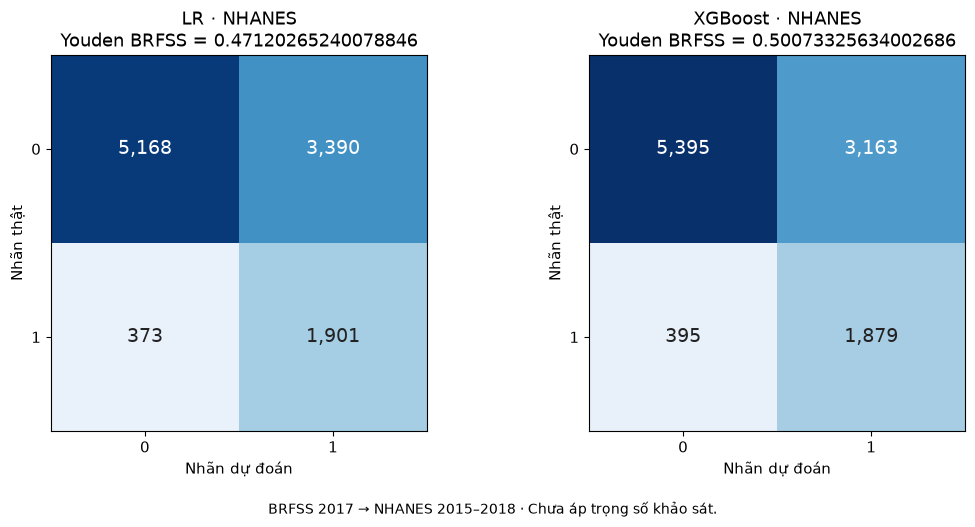

In [5]:
youden_metrics = overall_metrics.loc[overall_metrics["threshold_name"].eq("youden")].set_index("model")
vmax = youden_metrics[["tn", "fp", "fn", "tp"]].to_numpy().max()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.7))
for ax, model in zip(axes, ["LR", "XGBoost"]):
    row = youden_metrics.loc[model]
    matrix = row[["tn", "fp", "fn", "tp"]].to_numpy(dtype=int).reshape(2, 2)
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, f"{value:,}", ha="center", va="center", fontsize=14,
                color="white" if value > vmax / 2 else "#222222")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["0", "1"], yticklabels=["0", "1"],
           xlabel="Nhãn dự đoán", ylabel="Nhãn thật",
           title=f"{model} · NHANES\nYouden BRFSS = {reverse_thresholds[model]['youden']:.17g}")
fig.subplots_adjust(bottom=0.19, top=0.85, wspace=0.25)
fig.text(0.5, 0.045, "BRFSS 2017 → NHANES 2015–2018 · Chưa áp trọng số khảo sát.", ha="center", fontsize=10)
figure_paths.append(utils.save_png(fig, figures_dir / "nhanes_confusion_youden.png"))
plt.show()
plt.close(fig)

## Đối chiếu artifact

Hash trước/sau được ghi riêng cho pipeline, ngưỡng và metadata; các bảng dự đoán giữ đủ 8 đầu vào gốc để phân tích nhóm sau.

In [6]:
hash_rows = []
for filename, before in frozen_hashes.items():
    after = hashlib.sha256(filename.read_bytes()).hexdigest()
    assert after == before
    hash_rows.append({"file": str(filename.relative_to(project_dir)),
                      "sha256_before": before, "sha256_after": after, "unchanged": after == before})
hash_audit = pd.DataFrame(hash_rows)
hash_audit.to_csv(external_dir / "artifact_hashes.csv", index=False)
pd.testing.assert_frame_equal(nhanes_test, nhanes_before, check_exact=True)
pd.testing.assert_frame_equal(X_nhanes, nhanes_before[INPUT_COLS], check_exact=True)
pd.testing.assert_series_equal(y_nhanes, nhanes_before["diabetes_label"], check_exact=True)
for model, pipeline in pipelines.items():
    assert joblib.hash(pipeline) == memory_hashes[model]
    prediction = pd.read_parquet(external_dir / f"nhanes_{model}_predictions.parquet")
    assert len(prediction) == 10832 and prediction["SEQN"].is_unique
    pd.testing.assert_frame_equal(
        prediction[["SEQN", "cycle", "diabetes_label"] + INPUT_COLS],
        nhanes_before[["SEQN", "cycle", "diabetes_label"] + INPUT_COLS], check_exact=True,
    )
    for name, column in [("default", "prediction_0_5"), ("youden", "prediction_youden")]:
        np.testing.assert_array_equal(prediction[column],
            prediction["probability"].ge(reverse_thresholds[model][name]).astype(int))
manifest = {
    "reverse_run_id": REVERSE_RUN_ID, "development": "BRFSS 2017", "external": "NHANES 2015-2018",
    "rows": len(nhanes_test), "n_positive": int(y_nhanes.sum()), "n_negative": int(y_nhanes.eq(0).sum()),
    "input_columns": INPUT_COLS, "input_dtypes": X_nhanes.dtypes.astype(str).to_dict(),
    "thresholds": reverse_thresholds, "prediction_rule": "probability >= saved threshold",
    "survey_weighted": False, "calibration": None,
    "label_definitions": {"BRFSS": "self-reported diagnosed non-gestational diabetes",
                          "NHANES": "questionnaire, medication, HbA1c and usable glucose; existing negative-label assumption"},
    "frozen_artifacts_before": {str(p): digest for p, digest in frozen_hashes.items()},
    "frozen_artifacts_after": {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in frozen_hashes},
    "versions": reverse_config["versions"],
}
output_files = [p for p in external_dir.rglob("*") if p.is_file() and p.name != "manifest.json"] + figure_paths
assert all(p.suffix.lower() != ".pdf" for p in output_files)
manifest["output_sha256"] = {str(p.relative_to(project_dir)): hashlib.sha256(p.read_bytes()).hexdigest()
                            for p in output_files}
(external_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(hash_audit[["file", "unchanged"]])
display(probability_metrics.round(6))
display(threshold_metrics.round(6))

,file,unchanged
0,results\reverse_validation\official\58ba2320a9...,True
1,models\reverse_validation\58ba2320a9141ff0\LR....,True
2,results\reverse_validation\official\58ba2320a9...,True
3,results\reverse_validation\official\58ba2320a9...,True
4,models\reverse_validation\58ba2320a9141ff0\LR....,True
5,models\reverse_validation\58ba2320a9141ff0\LR....,True
6,results\reverse_validation\official\58ba2320a9...,True
7,models\reverse_validation\58ba2320a9141ff0\XGB...,True
8,results\reverse_validation\official\58ba2320a9...,True
9,results\reverse_validation\official\58ba2320a9...,True


,model,n,n_positive,n_negative,positive_rate,roc_auc,average_precision,brier
0,LR,10832,2274,8558,0.209934,0.789867,0.453029,0.209143
2,XGBoost,10832,2274,8558,0.209934,0.797822,0.472544,0.201333


,model,threshold_name,threshold,sensitivity,specificity,ppv,npv,f1,tn,fp,fn,tp,predicted_positive_rate
0,LR,default,0.500000,0.813105,0.636364,0.372707,0.927610,0.511126,5446,3112,425,1849,0.457995
1,LR,youden,0.471203,0.835972,0.603879,0.359289,0.932684,0.502578,5168,3390,373,1901,0.488460
2,XGBoost,default,0.500000,0.827617,0.629586,0.372526,0.932180,0.513787,5388,3170,392,1882,0.466396
3,XGBoost,youden,0.500733,0.826297,0.630404,0.372670,0.931779,0.513669,5395,3163,395,1879,0.465473


## Fairness trên NHANES

Dùng dự đoán đã lưu và đầu vào gốc trước imputation; metric chưa áp trọng số khảo sát.

| Thuộc tính | Nhóm |
|---|---|
| Giới | sex=1 Nam, sex=2 Nữ |
| Sắc tộc | White NH, Black NH, Hispanic, Other |
| Tuổi | 18–39, 40–59, ≥60 |
| BMI (kg/m²) | Thiếu cân <18,5; bình thường 18,5–<25; thừa cân 25–<30; béo phì ≥30 |

Missing là nhóm riêng cho từng thuộc tính.

In [1]:
import os
for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[variable] = "1"

from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
import src.utils as utils

FAIRNESS_RUN_ID = "58ba2320a9141ff0"
run_dir = project_dir / "results/brfss_to_nhanes/final_development" / FAIRNESS_RUN_ID
external_dir = project_dir / "results/brfss_to_nhanes/external_validation" / FAIRNESS_RUN_ID
fairness_dir = project_dir / "results/brfss_to_nhanes/fairness" / FAIRNESS_RUN_ID
figures_dir = project_dir / "results/brfss_to_nhanes/figures/fairness" / FAIRNESS_RUN_ID
fairness_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
external_manifest_path = external_dir / "manifest.json"
external_manifest = json.loads(external_manifest_path.read_text(encoding="utf-8"))
assert external_manifest["reverse_run_id"] == FAIRNESS_RUN_ID
assert external_manifest["development"] == "BRFSS 2017"
assert external_manifest["rows"] == 10832 and external_manifest["n_positive"] == 2274
source_path = project_dir / "data/processed/nhanes_2015_2018.parquet"
source_hash = hashlib.sha256(source_path.read_bytes()).hexdigest()
assert source_hash == utils.get_manifest_artifact_hash(
    external_manifest["frozen_artifacts_before"], source_path, project_dir
)
input_cols = external_manifest["input_columns"]
assert input_cols == ["age", "sex", "race_ethnicity", "bmi", "smoking_status",
                      "physical_activity", "heart_attack", "stroke"]
source_columns = ["SEQN", "cycle", "diabetes_label", "sex", "race_ethnicity", "age", "bmi"]
source = pd.read_parquet(source_path, columns=source_columns)
assert len(source) == 10832 and source["SEQN"].notna().all() and source["SEQN"].is_unique
assert source["diabetes_label"].value_counts().to_dict() == {0: 8558, 1: 2274}
source = source.set_index("SEQN", drop=False).sort_index()
frozen_hashes = {
    source_path: source_hash,
    external_manifest_path: hashlib.sha256(external_manifest_path.read_bytes()).hexdigest(),
}
predictions, group_labels, thresholds = {}, {}, {}
specs, comparison_groups = utils.get_fairness_group_specs()
group_order = {"sex": ["Nam", "Nữ", "Missing"],
               **{attribute: groups + ["Missing"] for attribute, groups in specs.items()}}
comparison_groups = {"sex": ["Nam", "Nữ"], **comparison_groups}
group_display = {
    "sex": {"Nam": "Nam", "Nữ": "Nữ", "Missing": "Missing"},
    "race_ethnicity": {group: group for group in group_order["race_ethnicity"]},
    "age": {"18-39": "18–39", "40-59": "40–59", "60+": "≥60", "Missing": "Missing"},
    "bmi": {"Underweight": "Thiếu cân", "Normal": "Bình thường", "Overweight": "Thừa cân",
            "Obese": "Béo phì", "Missing": "Missing"},
}
for model in ["LR", "XGBoost"]:
    prediction_path = external_dir / f"nhanes_{model}_predictions.parquet"
    digest = hashlib.sha256(prediction_path.read_bytes()).hexdigest()
    assert digest == utils.get_manifest_artifact_hash(
        external_manifest["output_sha256"], prediction_path, project_dir
    )
    frozen_hashes[prediction_path] = digest
    data = pd.read_parquet(prediction_path, columns=source_columns + ["probability", "prediction_youden"])
    assert len(data) == 10832 and data.index.is_unique and data["SEQN"].is_unique
    assert data["SEQN"].notna().all() and not data[["SEQN", "cycle"]].duplicated().any()
    assert set(data["SEQN"]) == set(source["SEQN"])
    data = data.set_index("SEQN", drop=False).reindex(source.index)
    pd.testing.assert_frame_equal(data[source_columns], source[source_columns], check_exact=True)
    assert data["probability"].notna().all() and data["probability"].between(0, 1).all()
    assert np.isfinite(data["probability"]).all()
    threshold_path = run_dir / model / "thresholds.json"
    digest = hashlib.sha256(threshold_path.read_bytes()).hexdigest()
    assert digest == utils.get_manifest_artifact_hash(
        external_manifest["frozen_artifacts_before"], threshold_path, project_dir
    )
    frozen_hashes[threshold_path] = digest
    saved_thresholds = json.loads(threshold_path.read_text(encoding="utf-8"))
    assert saved_thresholds == external_manifest["thresholds"][model]
    thresholds[model] = float(saved_thresholds["youden"])
    assert np.isfinite(thresholds[model])
    assert data["prediction_youden"].notna().all() and data["prediction_youden"].isin([0, 1]).all()
    np.testing.assert_array_equal(data["prediction_youden"],
                                  data["probability"].ge(thresholds[model]).astype(int))
    labels, current_specs = utils.get_fairness_groups(data)
    assert current_specs == specs and data["sex"].dropna().isin([1, 2]).all()
    labels["sex"] = data["sex"].map({1: "Nam", 2: "Nữ"}).astype("string").fillna("Missing")
    assert labels.index.equals(data.index) and not labels.isna().any().any()
    for attribute, groups in group_order.items():
        assert labels[attribute].isin(groups).all()
    predictions[model], group_labels[model] = data, labels

pd.testing.assert_frame_equal(predictions["LR"][source_columns], predictions["XGBoost"][source_columns])
pd.testing.assert_frame_equal(group_labels["LR"], group_labels["XGBoost"])
overall_path = external_dir / "overall_metrics.csv"
digest = hashlib.sha256(overall_path.read_bytes()).hexdigest()
assert digest == utils.get_manifest_artifact_hash(external_manifest["output_sha256"], overall_path, project_dir)
frozen_hashes[overall_path] = digest
overall_youden = pd.read_csv(overall_path).query("threshold_name == 'youden'").set_index("model")
display(pd.DataFrame([{"model": model, "n": len(data), "nhãn 1": int(data["diabetes_label"].sum()),
                       "Youden BRFSS": thresholds[model]} for model, data in predictions.items()]))

,model,n,nhãn 1,Youden BRFSS
0,LR,10832,2274,0.471203
1,XGBoost,10832,2274,0.500733


## Metric từng nhóm

Metric không xác định được giữ NA; AUC và AP cần đủ hai nhãn. Nhóm rỗng có số đếm 0 và metric NA.

In [2]:
group_rows, coverage_rows = [], []
for model, data in predictions.items():
    for attribute, groups in group_order.items():
        labels = group_labels[model][attribute]
        masks = [labels.eq(group) for group in groups]
        assert np.all(np.stack([mask.to_numpy(dtype=bool) for mask in masks]).sum(axis=0) == 1)
        for group, mask in zip(groups, masks):
            subset = data.loc[mask]
            metrics = utils.get_binary_group_metrics(
                subset["diabetes_label"], subset["probability"], subset["prediction_youden"]
            )
            if not (metrics["n_positive"] and metrics["n_negative"]):
                metrics["roc_auc"] = metrics["average_precision"] = np.nan
            group_rows.append({
                "cohort": "NHANES 2015–2018", "model": model, "attribute": attribute,
                "group": group, "group_label": group_display[attribute][group],
                "youden_threshold": thresholds[model],
                "included_in_gap": group in comparison_groups[attribute], **metrics,
            })
group_metrics = pd.DataFrame(group_rows)
for (model, attribute), groups in group_metrics.groupby(["model", "attribute"], sort=False):
    total = overall_youden.loc[model]
    row = {"model": model, "attribute": attribute}
    for column in ["n", "n_positive", "n_negative", "tn", "fp", "fn", "tp"]:
        row[column] = int(groups[column].sum())
        assert row[column] == total[column], (model, attribute, column)
    assert row["n"] == 10832
    row["matches_overall"] = True
    coverage_rows.append(row)
coverage_checks = pd.DataFrame(coverage_rows)
group_metrics.to_csv(fairness_dir / "group_metrics.csv", index=False, na_rep="NA")
coverage_checks.to_csv(fairness_dir / "group_count_checks.csv", index=False)
keys = ["model", "attribute", "group_label"]
display(group_metrics[keys + ["n", "n_positive", "n_negative", "positive_rate", "tn", "fp", "fn", "tp"]]
        .round(4).astype(object).fillna("NA"))
display(group_metrics[keys + ["tpr", "fpr", "ppv", "npv", "f1", "predicted_positive_rate"]]
        .round(4).astype(object).fillna("NA"))
display(group_metrics[keys + ["roc_auc", "average_precision", "brier"]]
        .round(4).astype(object).fillna("NA"))
display(coverage_checks)

,model,attribute,group_label,n,n_positive,n_negative,positive_rate,tn,fp,fn,tp
0,LR,sex,Nam,5222,1186,4036,0.2271,2424,1612,186,1000
1,LR,sex,Nữ,5610,1088,4522,0.1939,2744,1778,187,901
2,LR,sex,Missing,0,0,0,NA,0,0,0,0
3,LR,race_ethnicity,White NH,3633,668,2965,0.1839,1904,1061,118,550
4,LR,race_ethnicity,Black NH,2359,540,1819,0.2289,897,922,62,478
5,LR,race_ethnicity,Hispanic,2961,693,2268,0.234,1251,1017,99,594
6,LR,race_ethnicity,Other,1879,373,1506,0.1985,1116,390,94,279
7,LR,race_ethnicity,Missing,0,0,0,NA,0,0,0,0
8,LR,age,18–39,3720,170,3550,0.0457,3273,277,111,59
9,LR,age,40–59,3339,684,2655,0.2049,1591,1064,212,472


,model,attribute,group_label,tpr,fpr,ppv,npv,f1,predicted_positive_rate
0,LR,sex,Nam,0.8432,0.3994,0.3828,0.9287,0.5266,0.5002
1,LR,sex,Nữ,0.8281,0.3932,0.3363,0.9362,0.4784,0.4775
2,LR,sex,Missing,NA,NA,NA,NA,NA,NA
3,LR,race_ethnicity,White NH,0.8234,0.3578,0.3414,0.9416,0.4827,0.4434
4,LR,race_ethnicity,Black NH,0.8852,0.5069,0.3414,0.9353,0.4928,0.5935
5,LR,race_ethnicity,Hispanic,0.8571,0.4484,0.3687,0.9267,0.5156,0.5441
6,LR,race_ethnicity,Other,0.748,0.259,0.417,0.9223,0.5355,0.356
7,LR,race_ethnicity,Missing,NA,NA,NA,NA,NA,NA
8,LR,age,18–39,0.3471,0.078,0.1756,0.9672,0.2332,0.0903
9,LR,age,40–59,0.6901,0.4008,0.3073,0.8824,0.4252,0.46


,model,attribute,group_label,roc_auc,average_precision,brier
0,LR,sex,Nam,0.7927,0.4805,0.2069
1,LR,sex,Nữ,0.7874,0.43,0.2113
2,LR,sex,Missing,NA,NA,NA
3,LR,race_ethnicity,White NH,0.7999,0.4345,0.1937
4,LR,race_ethnicity,Black NH,0.7727,0.4563,0.2459
5,LR,race_ethnicity,Hispanic,0.7779,0.4749,0.2255
6,LR,race_ethnicity,Other,0.8197,0.4775,0.167
7,LR,race_ethnicity,Missing,NA,NA,NA
8,LR,age,18–39,0.7729,0.1626,0.0845
9,LR,age,40–59,0.7018,0.367,0.2255


,model,attribute,n,n_positive,n_negative,tn,fp,fn,tp,matches_overall
0,LR,sex,10832,2274,8558,5168,3390,373,1901,True
1,LR,race_ethnicity,10832,2274,8558,5168,3390,373,1901,True
2,LR,age,10832,2274,8558,5168,3390,373,1901,True
3,LR,bmi,10832,2274,8558,5168,3390,373,1901,True
4,XGBoost,sex,10832,2274,8558,5395,3163,395,1879,True
5,XGBoost,race_ethnicity,10832,2274,8558,5395,3163,395,1879,True
6,XGBoost,age,10832,2274,8558,5395,3163,395,1879,True
7,XGBoost,bmi,10832,2274,8558,5395,3163,395,1879,True


## TPR và FPR

Mỗi hình đặt LR/XGBoost cạnh nhau, dùng cùng thang tỷ lệ. Thiếu cân và Missing của BMI được đánh dấu là nhóm mô tả.

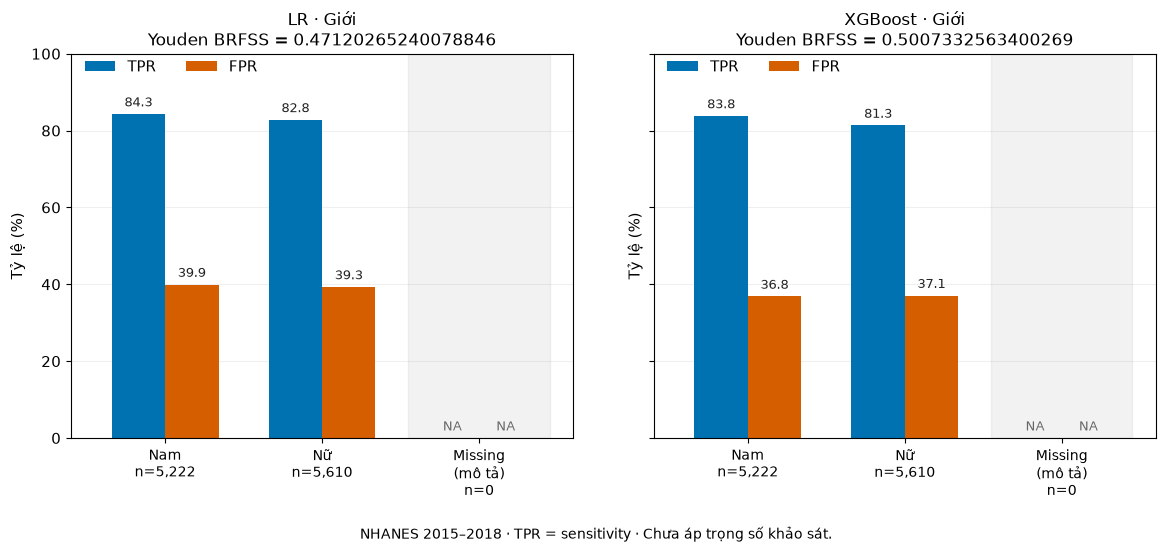

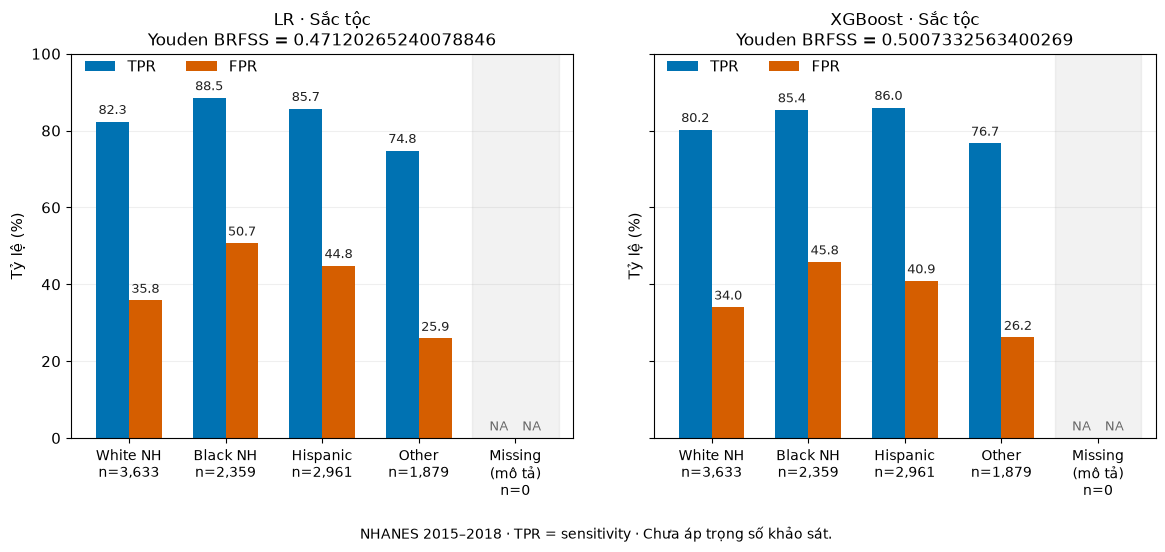

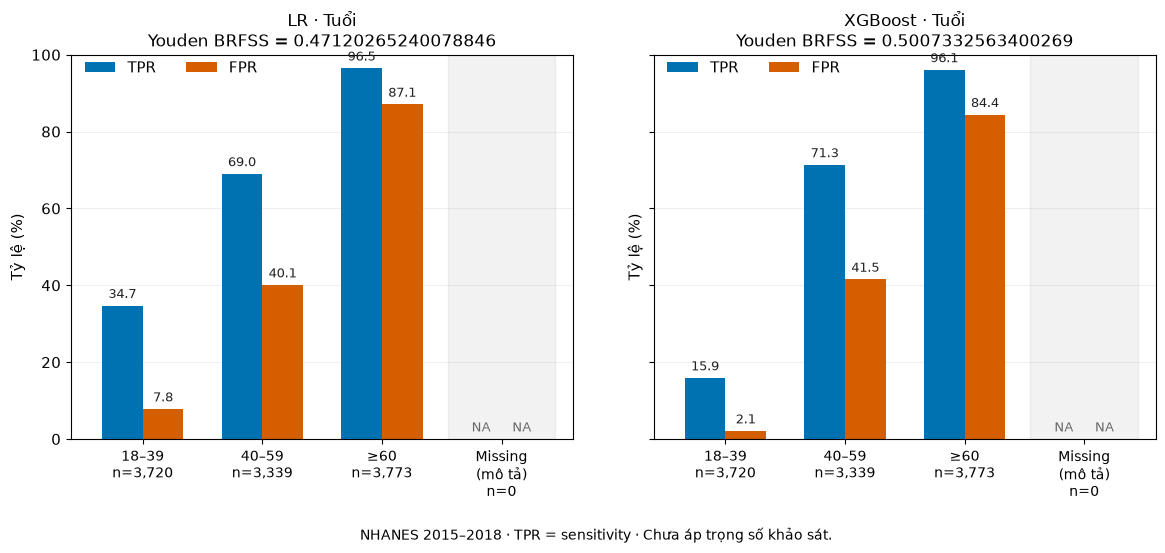

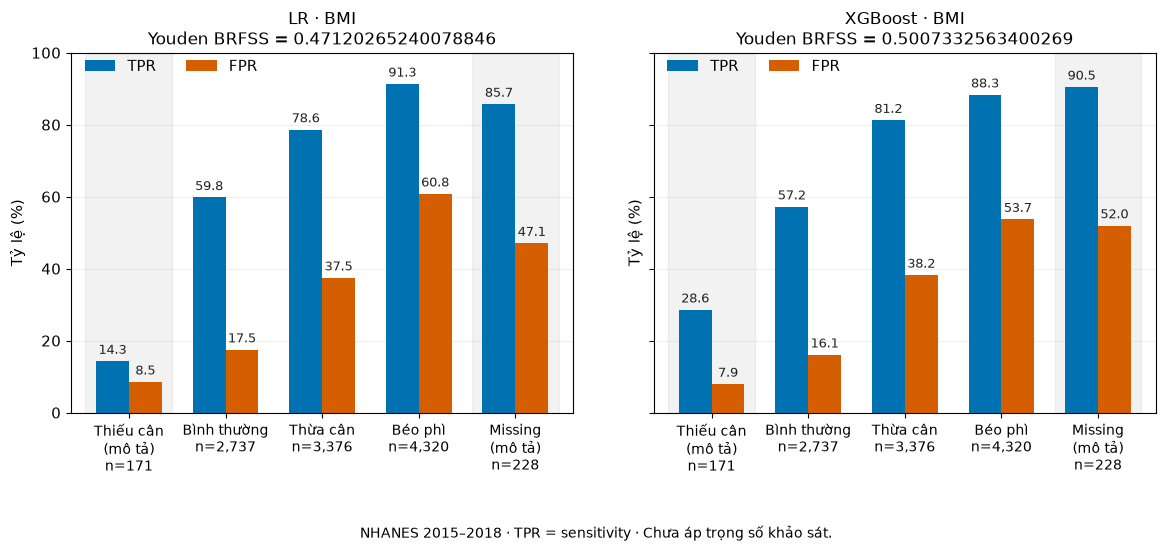

In [3]:
attribute_titles = {"sex": "Giới", "race_ethnicity": "Sắc tộc", "age": "Tuổi", "bmi": "BMI"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11})
figure_paths = []
for attribute, order in group_order.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.1), sharey=True)
    positions, width = np.arange(len(order)), 0.34
    for ax, model in zip(axes, ["LR", "XGBoost"]):
        groups = group_metrics.loc[
            group_metrics["model"].eq(model) & group_metrics["attribute"].eq(attribute)
        ].set_index("group").loc[order]
        for i, group in enumerate(order):
            if group not in comparison_groups[attribute]:
                ax.axvspan(i - 0.45, i + 0.45, color="#888888", alpha=0.10)
        for metric, label, offset, color in [
            ("tpr", "TPR", -width / 2, "#0072B2"),
            ("fpr", "FPR", width / 2, "#D55E00"),
        ]:
            values = groups[metric].to_numpy(dtype=float) * 100
            ax.bar(positions + offset, values, width, label=label, color=color)
            for x, value in zip(positions + offset, values):
                ax.text(x, value + 1.2 if np.isfinite(value) else 1.2,
                        f"{value:.1f}" if np.isfinite(value) else "NA",
                        ha="center", va="bottom", fontsize=9,
                        color="#222222" if np.isfinite(value) else "#666666")
        ticklabels = []
        for group in order:
            label = group_display[attribute][group]
            if group not in comparison_groups[attribute]:
                label += "\n(mô tả)"
            ticklabels.append(f"{label}\nn={int(groups.loc[group, 'n']):,}")
        ax.set(xticks=positions, xticklabels=ticklabels,
               xlim=(-0.6, len(order) - 0.4), ylim=(0, 100), ylabel="Tỷ lệ (%)",
               title=f"{model} · {attribute_titles[attribute]}\nYouden BRFSS = {thresholds[model]!r}")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper left", bbox_to_anchor=(0, 1.02), ncol=2, frameon=False)
        ax.tick_params(axis="x", labelsize=10)
    fig.subplots_adjust(bottom=0.25 if attribute == "bmi" else 0.21, top=0.84, wspace=0.16)
    fig.text(0.5, 0.045, "NHANES 2015–2018 · TPR = sensitivity · Chưa áp trọng số khảo sát.",
             ha="center", fontsize=10)
    figure_paths.append(utils.save_png(fig, figures_dir / f"tpr_fpr_{attribute}.png"))
    plt.show()
    plt.close(fig)

## Gap theo thuộc tính

Giới lấy Nam − Nữ; các thuộc tính còn lại lấy max − min, đơn vị điểm phần trăm. EO gap là max(|TPR gap|, |FPR gap|); BMI chính chỉ gồm bình thường, thừa cân và béo phì, các gap đều bỏ Missing.

In [4]:
gap_parts = []
for attribute, comparisons in comparison_groups.items():
    selected = group_metrics.loc[group_metrics["attribute"].eq(attribute)]
    # Hàm gap hiện có dùng tên year cho khóa tập đánh giá.
    adapter = selected.rename(columns={"cohort": "year"})
    if attribute == "sex":
        gaps = utils.get_sex_metric_gaps(adapter.rename(columns={"group": "sex_group"}))
        direction = "Nam - Nữ"
    else:
        gaps = utils.get_multigroup_metric_gaps(adapter, "group", comparisons)
        direction = "max - min"
    gaps = gaps.rename(columns={"year": "cohort"})
    gaps["attribute"], gaps["direction"] = attribute, direction
    gaps["comparison_groups"] = ", ".join(comparisons)
    comparison_n = selected.loc[selected["group"].isin(comparisons)].groupby("model")["n"].sum()
    gaps["comparison_n"] = gaps["model"].map(comparison_n)
    for _, row in gaps.iterrows():
        values = selected.loc[selected["model"].eq(row["model"])].set_index("group").loc[comparisons]
        for metric in ["tpr", "fpr", "ppv", "predicted_positive_rate"]:
            observed = values[metric].to_numpy(dtype=float)
            if np.isfinite(observed).all():
                expected = (observed[0] - observed[1] if attribute == "sex"
                            else observed.max() - observed.min()) * 100
            else:
                expected = np.nan
            np.testing.assert_allclose(row[f"{metric}_gap_pp"], expected, rtol=0, atol=1e-12, equal_nan=True)
        components = np.array([row["tpr_gap_pp"], row["fpr_gap_pp"]], dtype=float)
        expected_eo = np.abs(components).max() if np.isfinite(components).all() else np.nan
        np.testing.assert_allclose(row["equalized_odds_gap_pp"], expected_eo,
                                   rtol=0, atol=1e-12, equal_nan=True)
    gap_parts.append(gaps)
group_gaps = pd.concat(gap_parts, ignore_index=True)
group_gaps.to_csv(fairness_dir / "group_gaps_pp.csv", index=False, na_rep="NA")
for name, expected in [("group_metrics.csv", group_metrics),
                       ("group_count_checks.csv", coverage_checks),
                       ("group_gaps_pp.csv", group_gaps)]:
    restored = pd.read_csv(fairness_dir / name, float_precision="round_trip")
    pd.testing.assert_frame_equal(restored, expected.reset_index(drop=True), check_dtype=False,
                                  check_exact=True)
single_class = (group_metrics["n_positive"].eq(0) | group_metrics["n_negative"].eq(0))
assert group_metrics.loc[single_class, ["roc_auc", "average_precision"]].isna().all().all()
from PIL import Image
assert len(list(figures_dir.glob("*.png"))) == 4
for image_path in figure_paths:
    with Image.open(image_path) as image:
        assert image.format == "PNG" and all(abs(dpi - 300) < 0.1 for dpi in image.info["dpi"])
hash_rows = []
for filename, before in frozen_hashes.items():
    after = hashlib.sha256(filename.read_bytes()).hexdigest()
    assert after == before
    hash_rows.append({"file": str(filename.relative_to(project_dir)),
                      "sha256_before": before, "sha256_after": after, "unchanged": True})
pd.DataFrame(hash_rows).to_csv(fairness_dir / "source_hashes.csv", index=False)
for data in predictions.values():
    pd.testing.assert_frame_equal(data[source_columns], source[source_columns], check_exact=True)
manifest = {
    "reverse_run_id": FAIRNESS_RUN_ID, "external": "NHANES 2015-2018", "n": 10832,
    "source": "saved external predictions; original pre-imputation inputs",
    "thresholds_youden_brfss": thresholds, "threshold_policy": "fixed per model, shared by all groups",
    "group_order": group_order, "comparison_groups": comparison_groups,
    "age_boundaries": [18, 40, 60], "bmi_boundaries": [0, 18.5, 25, 30],
    "intervals": "left-closed, right-open; last age/BMI group unbounded",
    "missing": "separate descriptive group; excluded from gaps",
    "bmi_underweight": "descriptive only; excluded from primary BMI gaps",
    "gap_unit": "percentage points", "sex_gap": "male - female", "multigroup_gap": "max - min",
    "eo_gap": "max(abs(TPR gap), abs(FPR gap)); NA if either is undefined",
    "survey_weighted": False, "confidence_intervals": False, "statistical_tests": False,
    "source_sha256": {str(p.relative_to(project_dir)): digest for p, digest in frozen_hashes.items()},
    "utils_sha256": hashlib.sha256((project_dir / "src/utils.py").read_bytes()).hexdigest(),
}
output_files = [p for p in fairness_dir.rglob("*") if p.is_file() and p.name != "manifest.json"] + figure_paths
assert len(figure_paths) == 4 and not any(p.suffix.lower() == ".pdf" for p in output_files)
manifest["output_sha256"] = {str(p.relative_to(project_dir)): hashlib.sha256(p.read_bytes()).hexdigest()
                            for p in output_files}
(fairness_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(group_gaps[["model", "attribute", "direction", "comparison_n", "tpr_gap_pp", "fpr_gap_pp",
                    "ppv_gap_pp", "predicted_positive_rate_gap_pp", "equalized_odds_gap_pp"]]
        .round(2).astype(object).fillna("NA"))

,model,attribute,direction,comparison_n,tpr_gap_pp,fpr_gap_pp,ppv_gap_pp,predicted_positive_rate_gap_pp,equalized_odds_gap_pp
0,LR,sex,Nam - Nữ,10832,1.5,0.62,4.65,2.27,1.5
1,XGBoost,sex,Nam - Nữ,10832,2.47,-0.22,5.51,1.86,2.47
2,LR,race_ethnicity,max - min,10832,13.72,24.79,7.56,23.74,24.79
3,XGBoost,race_ethnicity,max - min,10832,9.33,19.63,7.37,18.66,19.63
4,LR,age,max - min,10832,61.77,79.28,22.51,81.59,79.28
5,XGBoost,age,max - min,10832,80.17,82.32,13.98,86.07,82.32
6,LR,bmi,max - min,10433,31.55,43.31,10.82,48.01,43.31
7,XGBoost,bmi,max - min,10433,31.11,37.65,12.16,43.64,37.65


## Nhận xét

Gap EO theo tuổi lớn nhất: LR 79,28 và XGBoost 82,32 điểm phần trăm; gap theo giới lần lượt 1,50 và 2,47. XGBoost có gap EO theo sắc tộc và BMI thấp hơn LR trong mẫu này.

BMI thiếu cân (171 người) và Missing (228 người) chỉ mô tả. Chênh lệch quan sát chưa cho biết nguyên nhân hay phân biệt đối xử.